# 7. Figures: the four thesis exhibits with their source numbers

The figures are rendered by `scripts/render_figures.py` (pipeline step 8) and ship in `outputs/figures/`. This notebook is the QA companion: it displays each shipped figure next to the numbers it encodes, read live from the canonical estimate CSVs. It is never the source of a thesis number.

Naming: files are named by thesis figure number (`fig1`...`fig4`); all appendix exhibits are tables (`outputs/tables/appendix/`).

In [1]:
import os, pathlib
import numpy as np
import pandas as pd
from IPython.display import Image, display

if pathlib.Path.cwd().name == "analysis":
    os.chdir(pathlib.Path.cwd().parent)   # notebooks execute from analysis/

t = pd.read_csv("outputs/estimates/timing_estimates.csv")   # 3_time_to_event.R
g = pd.read_csv("outputs/estimates/grant_estimates.csv")    # 4_matched_grants.R

def row(df, run_id):
    return df[df.run_id == run_id].iloc[0]


## Figure 1: Financing states by month since founding
Share of firms by state (no recorded financing / grant only / private only / both) over months 0–60, circular vs non-circular; month-verified sample. Purely descriptive (counts from `panel_events.parquet`).

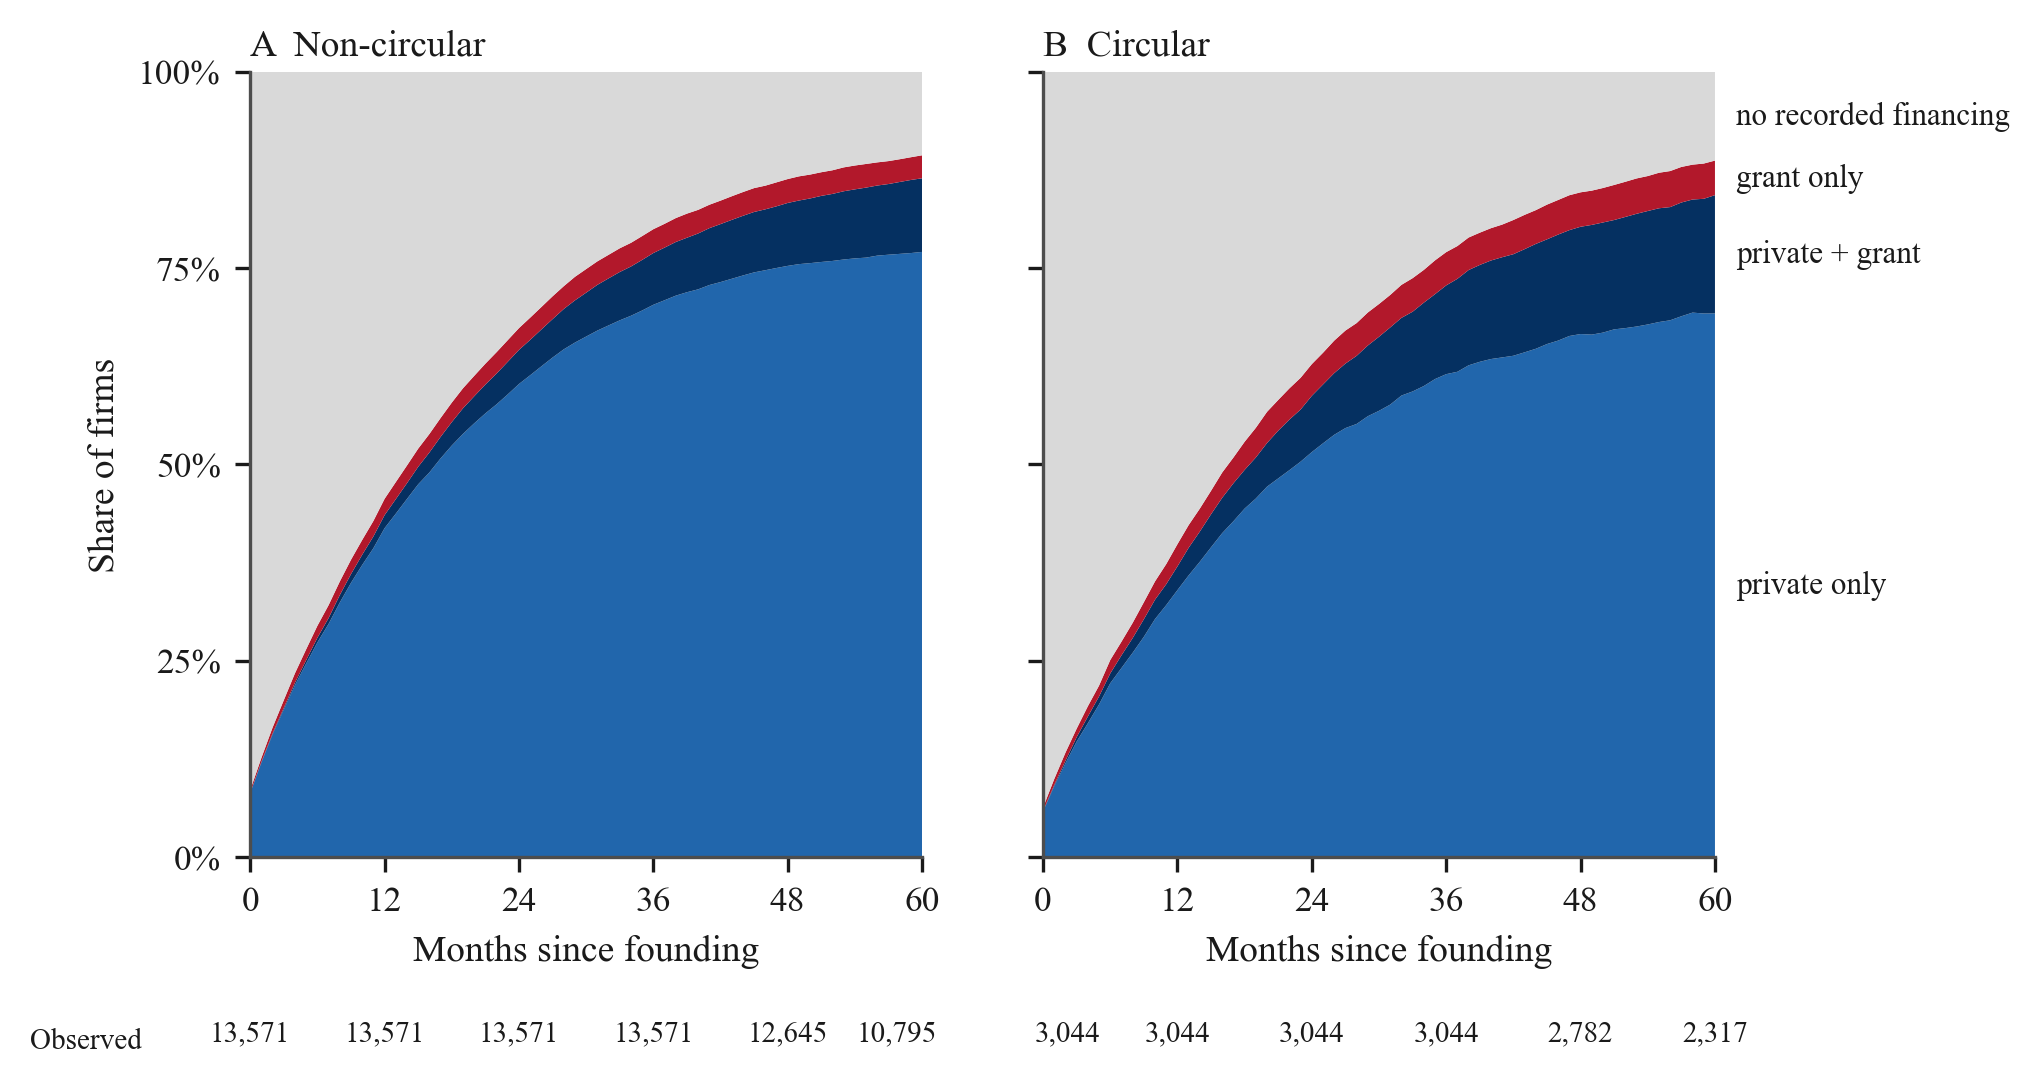

In [2]:
display(Image("outputs/figures/fig1_financing_states.png"))

## Figure 2: Time to first private round (KM, month-verified)
Cumulative probability of a first private round, circular vs non-circular. Source curve data: `outputs/estimates/timing_km_private.csv` (sample `main`).

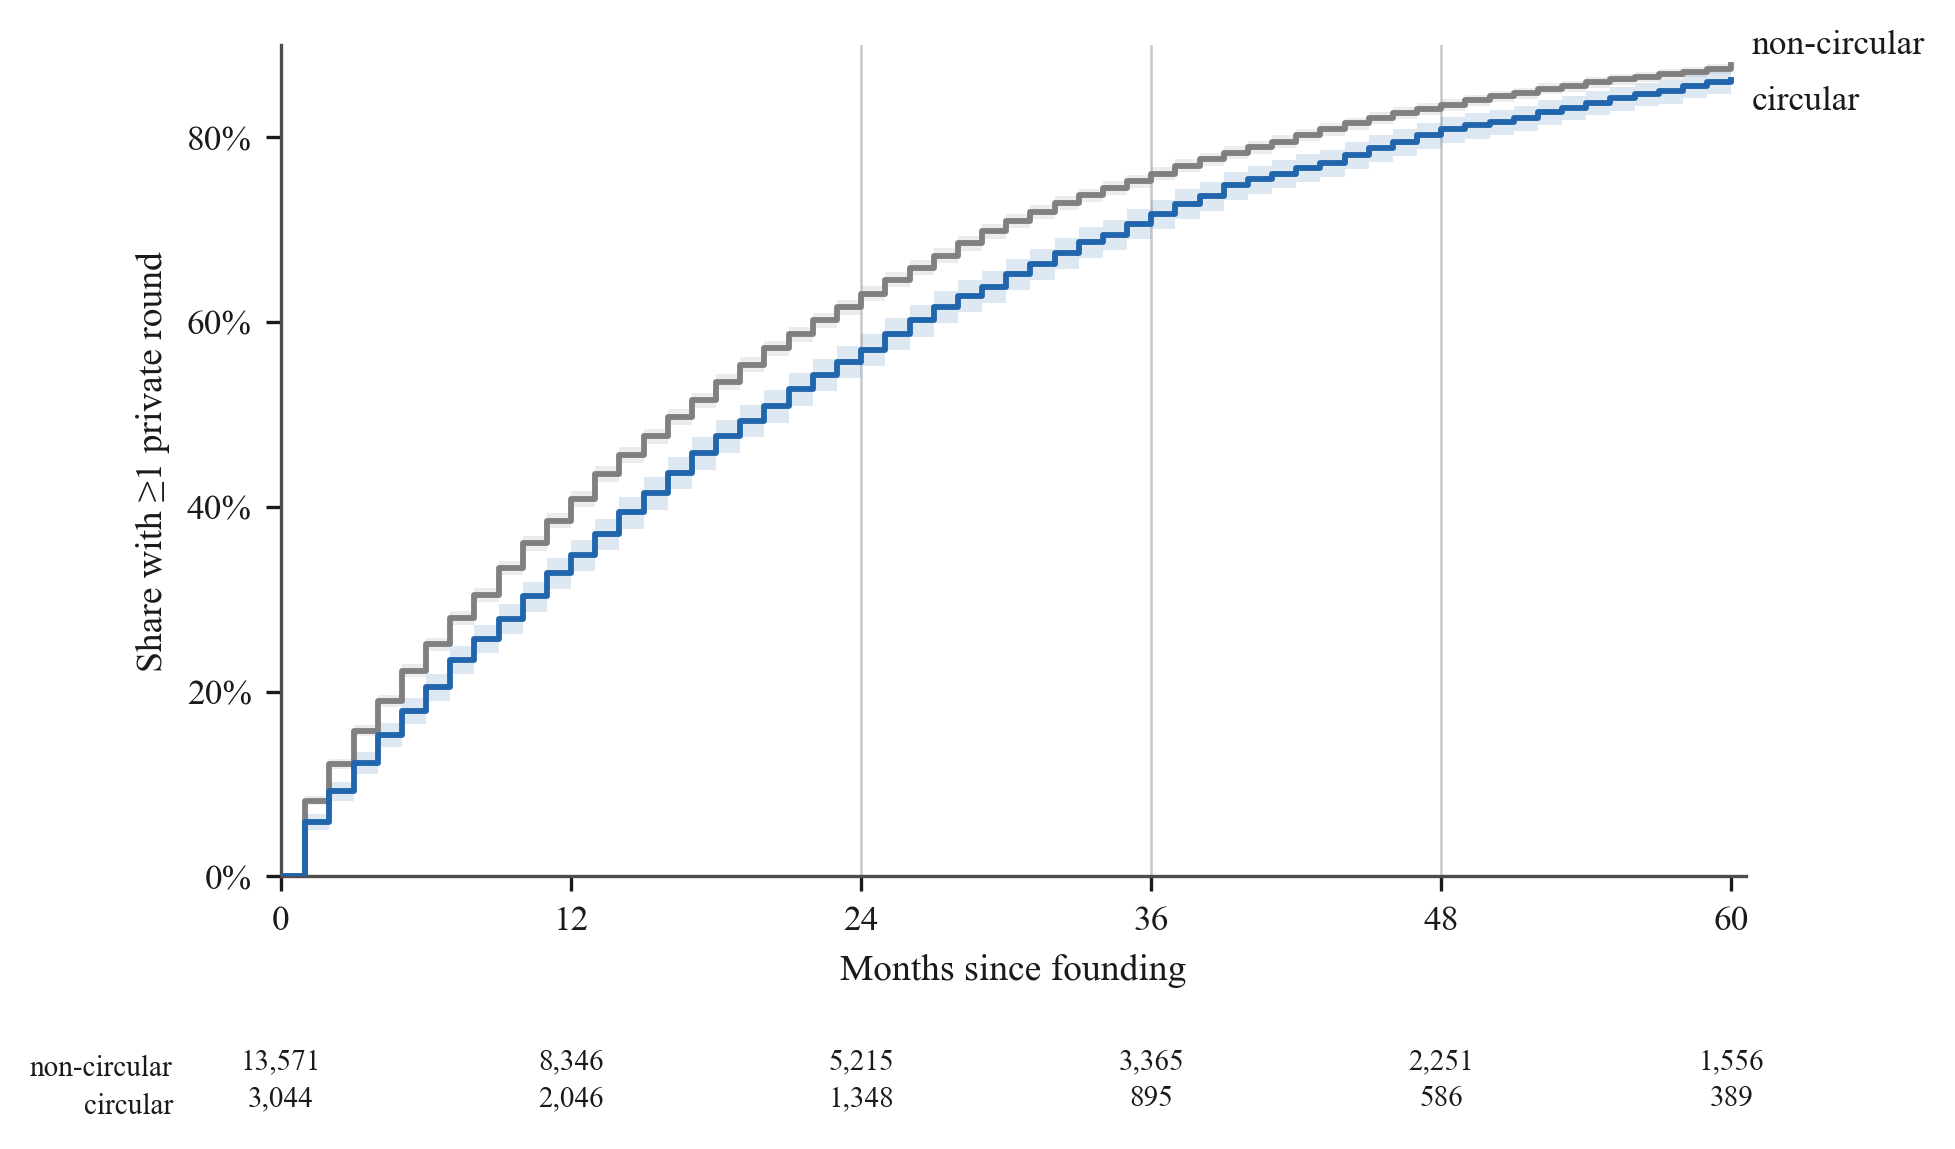

S2 incidence gap @36m: -2.42 pp (se 0.88, p = 0.00593, n = 16,615)
Cox HR S1: 0.876 (p = 4.39e-10)
Cox HR S2: 0.946 (p = 0.0133)


In [3]:
display(Image("outputs/figures/fig2_time_to_private.png"))
r = row(t, "V2_S2_fund36_private_v2")
print(f"S2 incidence gap @36m: {100*r.estimate:+.2f} pp "
      f"(se {100*r.se:.2f}, p = {r.p:.3g}, n = {r.n:,.0f})")
for rid, lab in (("V2_HAZ_S1_first_private", "Cox HR S1"),
                 ("V2_HAZ_S2_first_private", "Cox HR S2")):
    r = row(t, rid)
    print(f"{lab}: {np.exp(r.estimate):.3f} (p = {r.p:.3g})")

## Figure 3: Award panel: pre-dynamics + post-award transition
Panel A: treated-minus-control quarterly funding rates before the (pseudo-)award (`grants_predynamics_mv.csv`, flat pre-trends). Panel B: KM of a subsequent private round, recipients vs matched controls (`grants_km_postgrant.csv`, pure-grant sets).

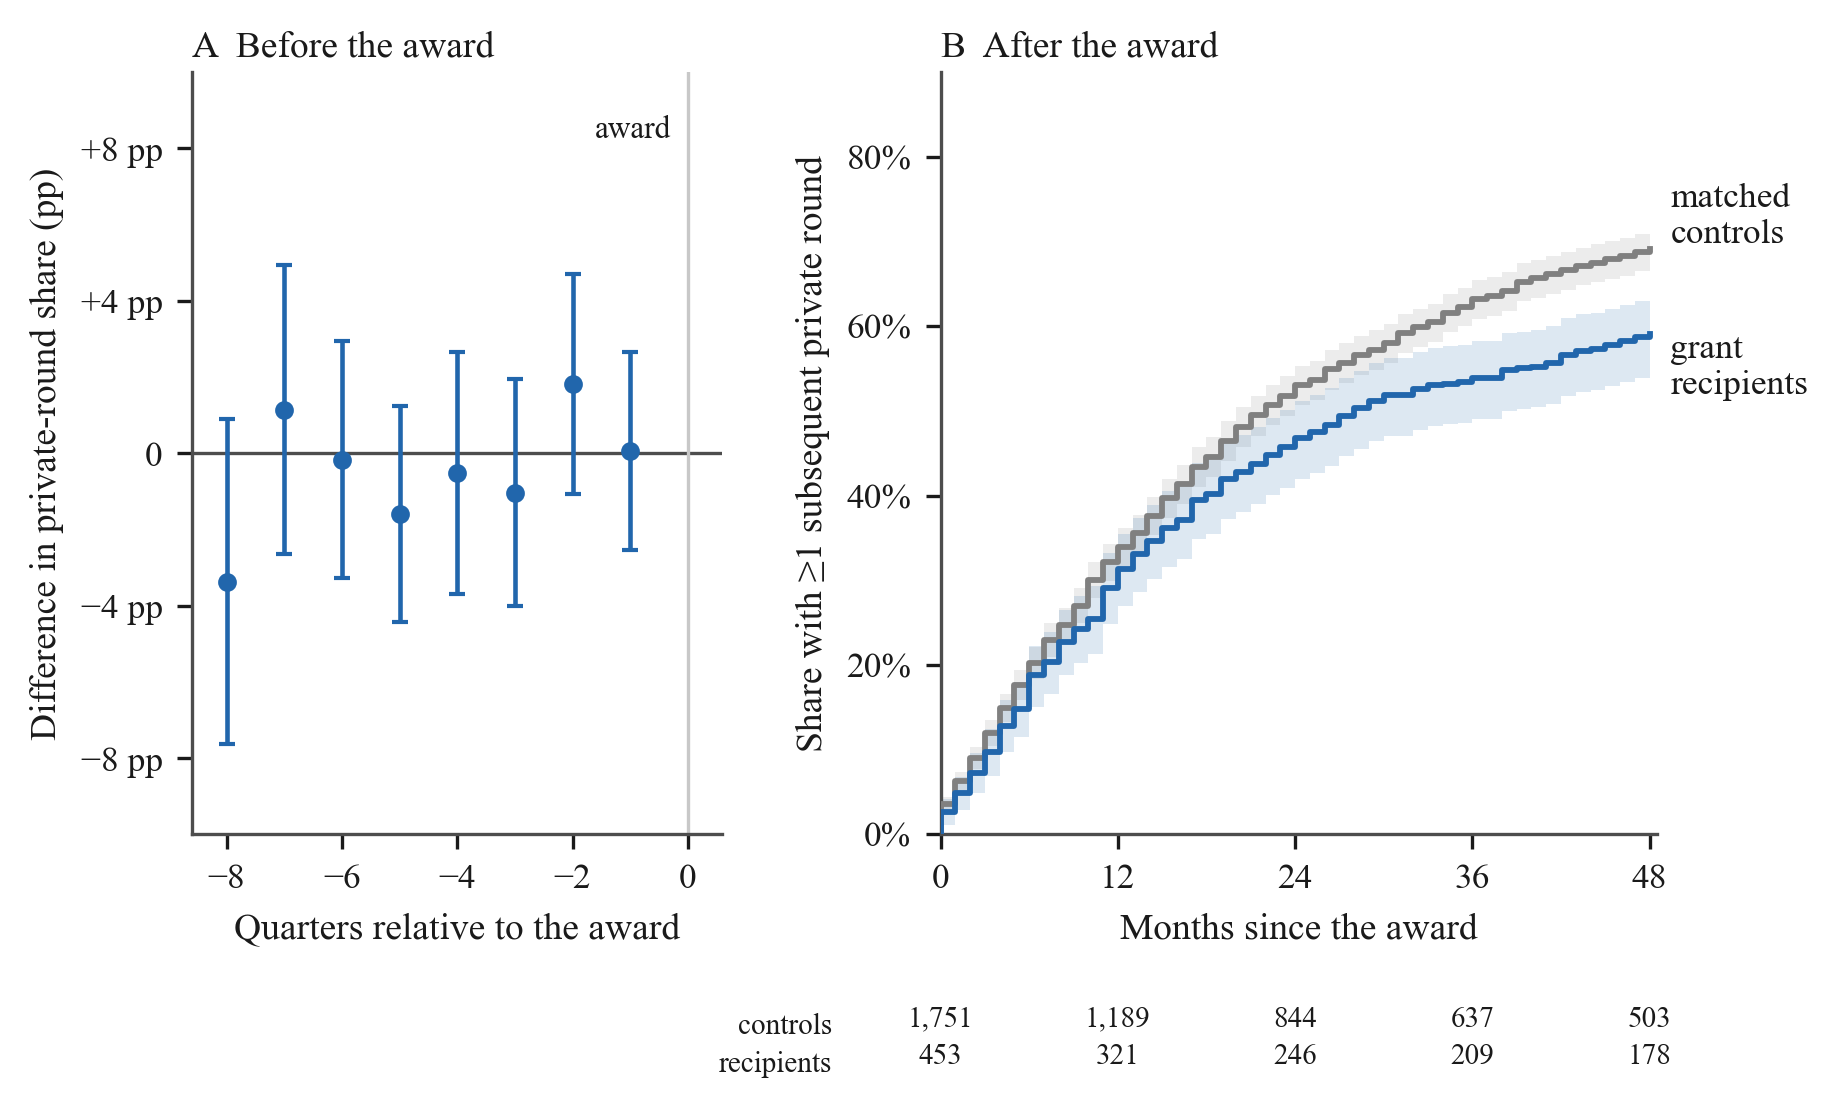

ATT (M1, pure grants): -6.08 pp (p = 0.02, sets = 453)
ATT (M2, +founders):   -7.95 pp (p = 0.00187)
TRANS HR (M2):         0.709 (p = 1.67e-06)


In [4]:
display(Image("outputs/figures/fig3_award_panel.png"))
r = row(g, "V2_M1_grant_only")
print(f"ATT (M1, pure grants): {100*r.estimate:+.2f} pp "
      f"(p = {r.p:.3g}, sets = {r.n_sets:.0f})")
r = row(g, "V2_M2_grant_only")
print(f"ATT (M2, +founders):   {100*r.estimate:+.2f} pp (p = {r.p:.3g})")
r = row(g, "V2_TRANS_M2_grant_only")
print(f"TRANS HR (M2):         {np.exp(r.estimate):.3f} (p = {r.p:.3g})")

## Figure 4: Post-award KM by pre-award financing status (bridge split)
No-prior sets (first-entry question) vs prior sets (acceleration question). Source curve data: `outputs/estimates/grants_km_bridge.csv`.

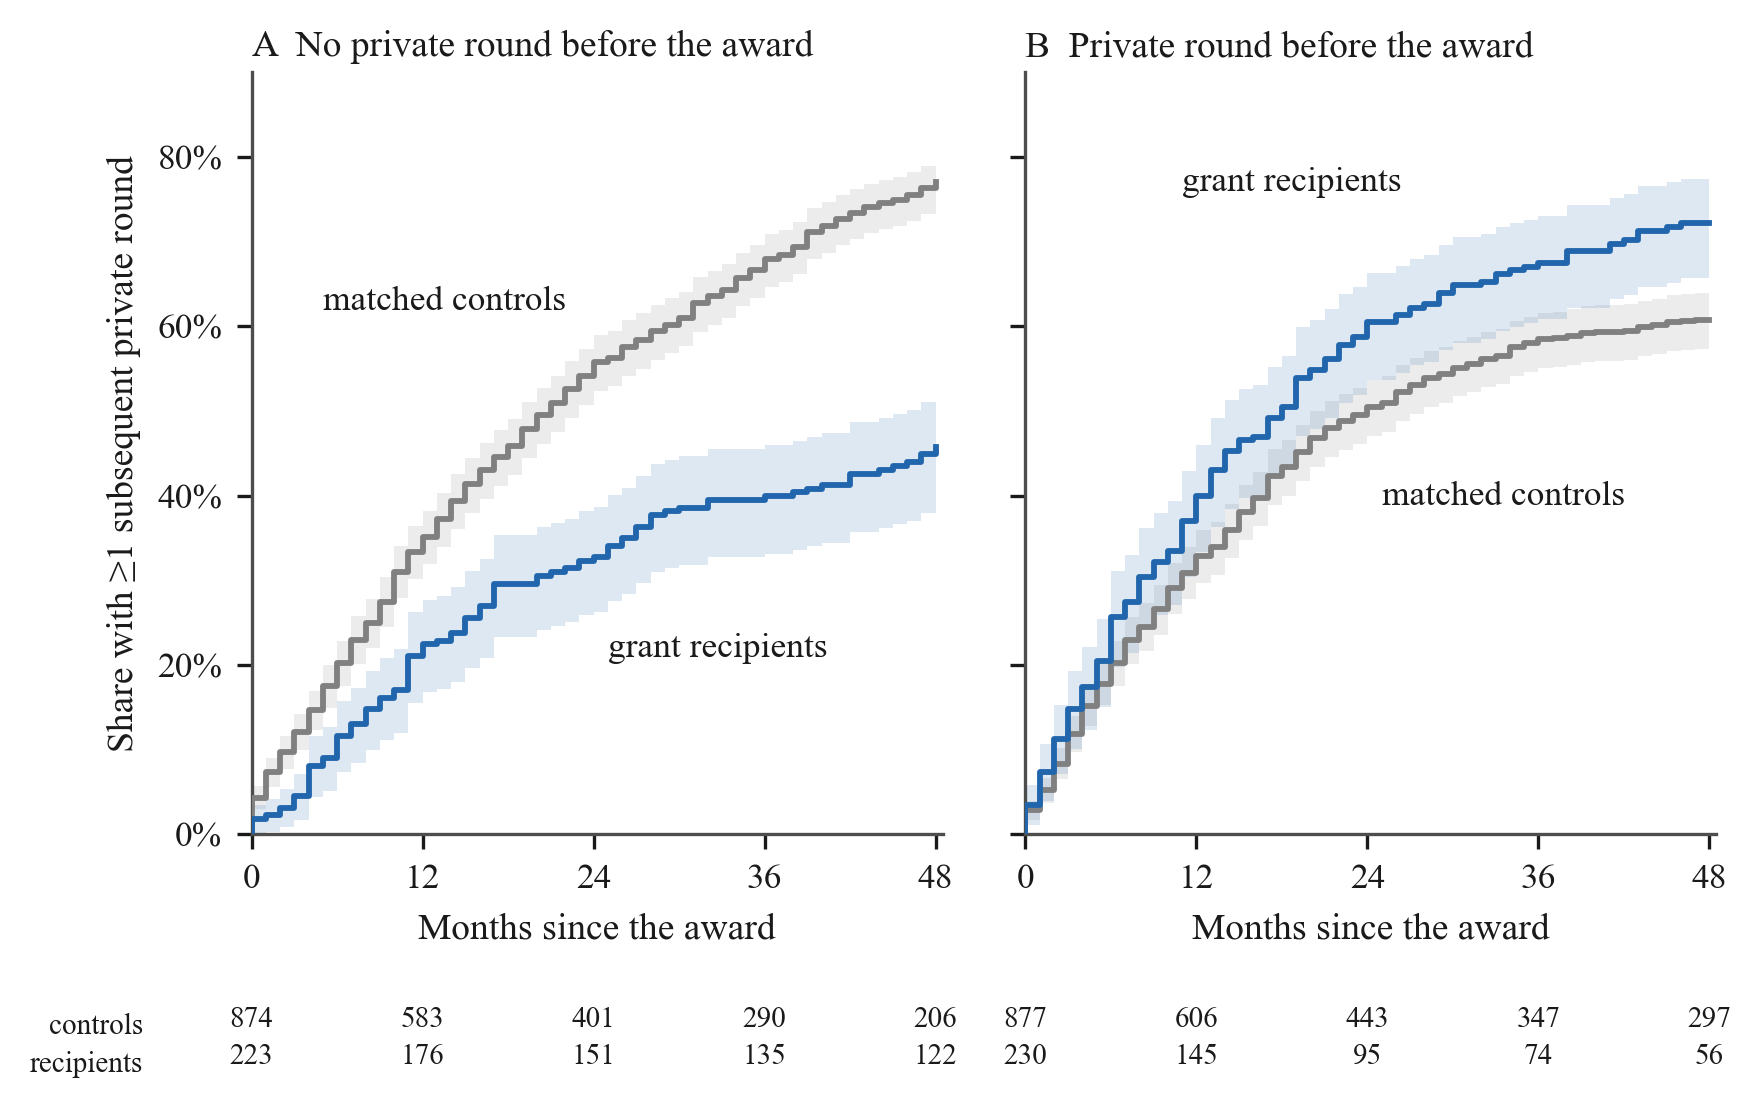

ATT never-private sets: -21.76 pp (p = 3.66e-09)
ATT previously-private sets: +9.27 pp (p = 0.00947)
difference test (treated x prior): +31.03 pp (p = 1.26e-09)


In [5]:
display(Image("outputs/figures/fig4_bridge_km.png"))
for rid, lab in (("V2_run_bridge_noprior", "never-private sets"),
                 ("V2_run_bridge_prior",   "previously-private sets")):
    r = row(g, rid)
    print(f"ATT {lab}: {100*r.estimate:+.2f} pp (p = {r.p:.3g})")
d = g[(g.run_id == "V2_run_bridge_diff") & (g.term == "treated:pre_any")].iloc[0]
print(f"difference test (treated x prior): {100*d.estimate:+.2f} pp (p = {d.p:.3g})")